# 1. Título

## Detección de ofertas de empleo fraudulentas a partir del lenguaje: un detector por capas lingüísticas evaluado con control de industria y de anuncios copiados en el corpus EMSCAD

**Leo Yahir Carpio Ángeles**  
Procesamiento de Lenguaje Natural · Proyecto semestral · 16 de noviembre de 2026

# 2. Resumen / Abstract


**Objetivo.** Construir un detector de ofertas de empleo fraudulentas a partir del texto del anuncio y evaluarlo de forma realista, descontando el sector económico y los anuncios copiados, dos factores que inflan los resultados en el corpus EMSCAD.

**Métodos.** Del corpus limpio (14,265 anuncios, 680 fraudulentos) obtuve cinco capas de rasgos: omisión y estructura, léxico TF-IDF, morfosintaxis, sintaxis de dependencias y semántica con `all-MiniLM-L6-v2`. Entrené una regresión logística por capa, las combiné por apilamiento y probé un modelo no lineal. Evalué con validación cruzada que mantiene juntos los anuncios de una misma campaña, con el AUC calculado solo entre anuncios de la misma industria y con una prueba que deja fuera una industria completa.

**Resultados.** El mejor detector es el léxico: AUC de 0.98 y precisión promedio de 0.85. Detecta el 80 % del fraude con una precisión de 0.77 (707 alertas en 14,265 anuncios) y la mitad con 0.97. No depende del sector (0.97 dentro de la industria, 0.89 en industrias no vistas), aunque su precisión promedio baja de 0.87 a 0.72 cuando las plantillas no pasan del entrenamiento a la prueba. Los 35 rasgos de forma, sin palabras de contenido, alcanzan 0.91 con un modelo no lineal y son los más estables entre sectores. La capa semántica es la más frágil: cae a 0.38 en el sector petrolero. Solo con la industria, sin leer el anuncio, ya se obtiene 0.73.

**Conclusión.** Se puede detectar la mayor parte del fraude con las palabras del anuncio, y la señal no es el sector: es el tipo de empleo que se ofrece como anzuelo, lo que el anuncio omite y su sintaxis más simple.


# 3. Introducción

Una oferta de empleo fraudulenta es un anuncio falso que busca obtener datos personales o dinero de quien se postula. El problema crece junto con el reclutamiento en línea, porque publicar un anuncio cuesta casi nada y la persona que busca trabajo tiene motivos para confiar. Vidros et al. (2017) publicaron el primer conjunto de datos abierto sobre el tema, EMSCAD, y señalaron que los anuncios falsos suelen tener textos cortos e información incompleta de la empresa. Los mismos autores mostraron que clasificadores sencillos alcanzan exactitudes altas con estos datos.

Mi proyecto busca construir un detector de este tipo, pero parte de una duda sobre esos números. Durante el semestre analicé el corpus en cinco prácticas (léxico, estadística, morfosintaxis, sintaxis y semántica) y en casi todas encontré el mismo obstáculo: **lo que separa a las dos clases a primera vista no es el engaño, sino el tema**. Las palabras más distintivas del fraude eran `aker`, `subsea` y `petroleum`, porque las estafas de EMSCAD se concentran en el sector petrolero. Además, una quinta parte del corpus original eran anuncios repetidos, de modo que un mismo texto puede quedar en el entrenamiento y en la prueba de un clasificador.

Las dos cosas son problemas conocidos. Kaufman et al. (2012) llaman fuga de información (*leakage*) al caso en que el modelo recibe durante el entrenamiento datos que no tendría al usarse de verdad, como las copias de los ejemplos de prueba. Geirhos et al. (2020) llaman aprendizaje por atajos (*shortcut learning*) al caso en que un modelo resuelve la tarea con una pista fácil que acompaña a la etiqueta en los datos, pero que no es el fenómeno que interesa. En este corpus el atajo sería el sector: un modelo puede aprender a reconocer anuncios petroleros en lugar de anuncios engañosos.

Por otro lado, la investigación sobre el lenguaje del engaño sugiere que mentir sí deja huellas en la forma del texto y no solo en el tema. Newman et al. (2003) encontraron que quienes mienten usan menos pronombres de primera persona y un lenguaje cognitivamente más simple, y Ott et al. (2011) mostraron que las reseñas falsas de hoteles se distinguen de las verdaderas por rasgos de estilo que las personas no detectan. Si esto se cumple en los anuncios de empleo, debería quedar señal en la gramática y en la estructura incluso al comparar anuncios del mismo sector.

**Objetivo.** Construir un detector de ofertas de empleo fraudulentas que use solo el texto del anuncio, y medir su desempeño de forma realista. Los objetivos específicos son tres: (1) representar cada anuncio con cinco capas de rasgos, una por cada nivel de análisis visto en el curso, y entrenar un detector con cada una y con su combinación; (2) evaluar los detectores con dos controles, validación cruzada que mantiene juntas las copias y prueba en una industria que el modelo nunca vio, para saber cuánto de su desempeño es detección de fraude y cuánto es reconocer el sector o una plantilla; y (3) identificar qué señales del lenguaje usa el detector.

**Hipótesis.** Antes de correr los experimentos escribí tres, sobre qué capas darían un detector confiable:

- **H1.** El léxico separa bien las clases en todo el corpus, pero es la capa que más pierde cuando la comparación se hace dentro de una misma industria.
- **H2.** La validación que ignora las copias sobreestima el desempeño.
- **H3.** Los rasgos de forma (omisión de secciones, gramática y sintaxis) conservan su capacidad dentro de la industria y en una industria no vista.

**Relevancia.** Un detector automático permite a una plataforma revisar a mano solo una fracción de los anuncios. Pero un detector que aprende el sector falla justo cuando más se necesita: cuando los estafadores cambian de sector. Por eso importa tanto el desempeño como saber de dónde viene, y las señales que no dependen del tema sirven además para orientar a quien busca trabajo sobre en qué fijarse.

# 4. Materiales

## 4.1 Conjunto de datos

Usé EMSCAD (*Employment Scam Aegean Dataset*), publicado por Vidros et al. (2017) con anuncios reales de la plataforma Workable recolectados entre 2012 y 2014 y etiquetados a mano por sus empleados. Trabajé con la copia que se distribuye en Kaggle como *Real or Fake Job Posting Prediction* (archivo `DataSet.csv`). Los autores lo publicaron para uso en investigación, y los datos personales (direcciones web, correos y teléfonos) ya vienen sustituidos por marcadores.

El archivo tiene 17,880 anuncios en inglés y 18 columnas. Cinco son texto libre (`title`, `company_profile`, `description`, `requirements` y `benefits`), con unos 7.3 millones de palabras en total. De los metadatos solo uso `industry`, que tiene 131 valores y falta en el 29 % de los anuncios, y la etiqueta `fraudulent`. No uso los metadatos no textuales (logotipo, salario, preguntas de filtro), porque el objetivo es estudiar el lenguaje.

Después de la limpieza quedan 14,265 anuncios y solo 680 son fraudulentos (4.8 %), así que las clases están muy desbalanceadas (ver la salida de la celda de carga). La definición de campaña se explica en la sección 5.1.


## 4.2 Artefactos de las prácticas anteriores

El proyecto no reprocesa el texto desde cero. Lee los archivos que generé en las cinco prácticas del curso, guardados en la carpeta `corpus_procesado/`:

| Archivo | Práctica | Contenido |
|---|---|---|
| `corpus_limpio.csv.gz` | 1 | Texto limpio, industria y categoría de los 14,265 anuncios |
| `corpus_tokens.jsonl.gz` | 1 | Oraciones y tokens de cada anuncio |
| `pos_por_documento.csv` | 3 | Proporción de cada categoría gramatical, pronombres y modales |
| `sintaxis_por_oracion.csv.gz` | 4 | Medidas de dependencias de 468,956 oraciones |
| `embeddings/sbert_documentos.npy` | 5 | Vector semántico de 384 dimensiones por anuncio |
| `embeddings/campanas.csv.gz` | 5 | Grupo de anuncios casi idénticos al que pertenece cada anuncio |

## 4.3 Software y equipo

Todo está escrito en Python 3.11 dentro de un cuaderno de Jupyter. La Tabla 2 lista las bibliotecas. El equipo fue una MacBook con procesador Apple M1 y 8 GB de memoria, con macOS 26.5. El cuaderno del proyecto tarda unos 14 minutos en ejecutarse completo, porque parte de los artefactos ya calculados. Generar esos artefactos desde el archivo original toma cerca de 25 minutos más, casi todo en el análisis de dependencias y en los vectores semánticos.

**Tabla 2.** Software utilizado.

| Herramienta | Versión | Uso |
|---|---|---|
| pandas, NumPy, SciPy | 3.0, 2.4, 1.17 | Tablas, cálculo numérico, grafos de copias y rangos |
| NLTK (Bird et al., 2009) | 3.9 | Segmentación, tokenización y etiquetas gramaticales (prácticas 1 a 3) |
| spaCy, modelo `en_core_web_sm` (Honnibal et al., 2020) | 3.8 | Análisis de dependencias (práctica 4) |
| sentence-transformers, modelo `all-MiniLM-L6-v2` (Reimers y Gurevych, 2019) | 5.2 | Vectores de oraciones (práctica 5) |
| scikit-learn (Pedregosa et al., 2011) | 1.9 | TF-IDF, regresión logística, *gradient boosting*, validación cruzada y métricas |
| Matplotlib | 3.10 | Figuras |

**Condiciones de uso.** Fijé la semilla aleatoria en 42 en las particiones, los modelos y el remuestreo. Todos los resultados de este documento salen del cuaderno `proyecto_final_NLP.ipynb`, que guarda las figuras en `figuras/` y las tablas en `resultados/`.

**Código de esta sección.** La primera celda prepara el entorno y muestra las versiones. La segunda carga el corpus, recupera las secciones de cada anuncio y le asigna su campaña.

In [1]:
import gzip, html, json, platform, re, time, unicodedata, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse import coo_matrix, csr_matrix, hstack
from scipy.sparse.csgraph import connected_components
from scipy.stats import rankdata
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler

AQUI = Path.cwd()
RUTA = next(p for p in [AQUI / "corpus_procesado", AQUI.parent / "corpus_procesado",
                        Path.home() / "Downloads" / "corpus_procesado"] if p.exists())
CSV_PATH = RUTA.parent / "DataSet.csv"
FIGURAS, RESULTADOS = AQUI / "figuras", AQUI / "resultados"
FIGURAS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)
SEMILLA = 42

AZUL, NARANJA, VERDE, GRIS, REJILLA, TENUE = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#dcdcd8", "#c9c8c3"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f2f1ee", NARANJA])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "axes.titlesize": 10.5,
    "axes.labelsize": 9.5, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False,
    "legend.fontsize": 8.5, "axes.edgecolor": REJILLA, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS,
})

def estilizar(ax, rejilla="x"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if rejilla:
        ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
        ax.set_axisbelow(True)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")
print("Artefactos:", RUTA)

Python 3.11.0 | pandas 3.0.6 | numpy 2.4.2 | scikit-learn 1.9.1 | scipy 1.17.1 | matplotlib 3.10.8
Artefactos: /Users/leocarpio/Downloads/corpus_procesado


In [2]:
# Misma limpieza de la Práctica 1. Se aplica al CSV original para recuperar qué secciones trae cada anuncio.
RE_ETIQUETA = re.compile(r"</?[a-zA-Z][^>]*>")
RE_BLOQUE = re.compile(r"</?(p|div|li|ul|ol|br|h[1-6]|tr|td|table|section)[^>]*>", re.I)
RE_ANONIMO = re.compile(r"#(?:URL|EMAIL|PHONE)_[0-9a-fA-F]+#")
RE_ESPACIOS = re.compile(r"[^\S\n]+")
RE_LINEAS = re.compile(r"\n\s*\n+")
TIPOGRAFICOS = str.maketrans({"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-", "…": "...",
                              " ": " ", "​": ""})

def limpiar(texto):
    t = html.unescape(html.unescape(texto))
    t = RE_BLOQUE.sub("\n", t)
    t = RE_ETIQUETA.sub(" ", t)
    t = RE_ANONIMO.sub(" ", t)
    t = unicodedata.normalize("NFKC", t).translate(TIPOGRAFICOS)
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = RE_LINEAS.sub("\n", RE_ESPACIOS.sub(" ", t))
    return "\n".join(linea.strip() for linea in t.split("\n")).strip()

SECCIONES = ["company_profile", "description", "requirements", "benefits"]
NOMBRE_SEC = {"company_profile": "Perfil de empresa", "description": "Descripción",
              "requirements": "Requisitos", "benefits": "Prestaciones"}

crudo = pd.read_csv(CSV_PATH)
crudo["texto_limpio"] = crudo[["title"] + SECCIONES].apply(
    lambda f: "\n".join(str(v).strip() for v in f if pd.notna(v)), axis=1).map(limpiar)
docs = pd.read_csv(RUTA / "corpus_limpio.csv.gz")
docs = docs.merge(crudo.drop_duplicates("texto_limpio")[["texto_limpio"] + SECCIONES], on="texto_limpio", how="left")
docs = docs.merge(pd.read_csv(RUTA / "embeddings" / "campanas.csv.gz"), on="doc_id", how="left")
docs["industria"] = docs["industry"].fillna("(sin industria)")

y = (docs["categoria"] == "Fraudulenta").to_numpy().astype(int)
campana = docs["campana"].to_numpy()
industria = docs["industria"].to_numpy()
con_industria = docs["industry"].notna().to_numpy()

resumen = pd.DataFrame({
    "Legítimas": [int((y == 0).sum()), docs.loc[y == 0, "campana"].nunique(),
                  int(docs.loc[y == 0, "n_tokens"].median()), f"{docs.loc[y == 0, 'industry'].isna().mean():.1%}"],
    "Fraudulentas": [int((y == 1).sum()), docs.loc[y == 1, "campana"].nunique(),
                     int(docs.loc[y == 1, "n_tokens"].median()), f"{docs.loc[y == 1, 'industry'].isna().mean():.1%}"],
}, index=["Documentos", "Campañas (grupos de anuncios casi iguales)", "Mediana de palabras", "Sin industria declarada"])
print(f"Registros originales: {len(crudo):,} | tras quitar duplicados: {len(docs):,} | "
      f"enlazados con sus secciones: {docs['description'].notna().mean():.1%}")
print(f"Tasa de fraude: {y.mean():.2%} | campañas: {docs['campana'].nunique():,} | "
      f"industrias: {docs['industry'].nunique()}\n")
print(resumen.to_string())
resumen.to_csv(RESULTADOS / "tabla1_corpus.csv")

Registros originales: 17,880 | tras quitar duplicados: 14,265 | enlazados con sus secciones: 100.0%
Tasa de fraude: 4.77% | campañas: 10,300 | industrias: 131

                                           Legítimas Fraudulentas
Documentos                                     13585          680
Campañas (grupos de anuncios casi iguales)      9803          506
Mediana de palabras                              381          247
Sin industria declarada                        29.1%        29.7%


# 5. Métodos

El proceso tiene cinco pasos. Cada uno responde a un problema que encontré en las prácticas.

## 5.1 Limpieza y eliminación de copias

Uní los cinco campos de texto de cada anuncio y quité el marcado HTML, los marcadores de anonimización y las variantes tipográficas de comillas y guiones. Después eliminé los anuncios repetidos comparando los primeros 400 caracteres del texto limpio, lo que redujo el corpus de 17,880 a 14,265 anuncios. Lo hice porque las copias exactas cuentan varias veces la misma evidencia.

Quitar copias exactas no basta, porque muchas empresas publican la misma plantilla con pequeños cambios (otra ciudad, otro título). Por eso agrupé los anuncios en **campañas**: dos anuncios pertenecen a la misma campaña si el coseno entre sus vectores semánticos es de 0.95 o más, y los grupos son las componentes conexas de esas uniones. Resultan 10,300 campañas, y las 680 ofertas fraudulentas se reducen a 506.

## 5.2 Cinco capas de rasgos

Cada anuncio se representa de cinco maneras, una por nivel de análisis. La Tabla 3 las resume. Agregué un modelo de referencia que solo conoce la industria del anuncio: mide cuánto se puede "detectar" sin leer una sola palabra.

**Tabla 3.** Capas de rasgos. Todas describen el mismo anuncio a distinto nivel.

| Capa | Rasgos | Qué mide |
|---|---|---|
| Tema (referencia) | 132 | Solo la industria declarada, sin texto |
| Omisión y estructura | 9 | Si existen el perfil de empresa, los requisitos y las prestaciones; palabras por sección; número de oraciones |
| Léxico | 60,000 | TF-IDF de palabras y pares de palabras, con frecuencia en escala logarítmica |
| Morfosintaxis | 18 | Proporción de sustantivos, verbos, adjetivos y otras categorías; pronombres (`we`, `our`, `you`, `your`); modales; oraciones sin verbo |
| Sintaxis | 8 | Longitud de oración, profundidad del árbol de dependencias, distancia de dependencia, subordinadas, oraciones con sujeto y con objeto |
| Semántica | 384 | Promedio de los vectores de las oraciones con `all-MiniLM-L6-v2` |

Además combiné las capas de dos maneras: **Forma** reúne omisión, morfosintaxis y sintaxis (35 rasgos que no contienen ninguna palabra de contenido), y **Todas las capas** reúne las cinco.

In [3]:
t0 = time.time()
palabras = lambda s: s.fillna("").map(limpiar).str.count(r"[A-Za-z]{2,}")
n_sec = pd.DataFrame({s: palabras(docs[s]) for s in SECCIONES})

# Capa 1. Omisión y estructura: qué secciones existen y cuánto se escribe.
estructura = pd.DataFrame({
    "Tiene perfil de empresa": (n_sec["company_profile"] > 0).astype(float),
    "Tiene requisitos": (n_sec["requirements"] > 0).astype(float),
    "Tiene prestaciones": (n_sec["benefits"] > 0).astype(float),
    "Palabras (log)": np.log1p(docs["n_tokens"]),
    "Oraciones (log)": np.log1p(docs["n_oraciones"]),
    "Palabras en perfil (log)": np.log1p(n_sec["company_profile"]),
    "Palabras en descripción (log)": np.log1p(n_sec["description"]),
    "Palabras en requisitos (log)": np.log1p(n_sec["requirements"]),
    "Palabras en prestaciones (log)": np.log1p(n_sec["benefits"]),
})

# Capa 3. Morfosintaxis: proporciones de categorías gramaticales, pronombres y modales (Práctica 3).
pos = pd.read_csv(RUTA / "pos_por_documento.csv").set_index("doc_id").reindex(docs["doc_id"])
NOMBRE_POS = {"NOUN": "Sustantivos", "VERB": "Verbos", "ADJ": "Adjetivos", "ADV": "Adverbios", "PRON": "Pronombres",
              "ADP": "Preposiciones", "DET": "Determinantes", "CONJ": "Conjunciones", "NUM": "Números",
              "pron_we": "we", "pron_our": "our", "pron_you": "you", "pron_your": "your",
              "md_will": "will", "md_can": "can", "md_must": "must", "md_should": "should",
              "sin_verbo": "Oraciones sin verbo"}
morfo = pos[list(NOMBRE_POS)].rename(columns=NOMBRE_POS).reset_index(drop=True).fillna(0.0)

# Capa 4. Sintaxis: promedios por documento de las medidas de dependencias (Práctica 4).
sint = pd.read_csv(RUTA / "sintaxis_por_oracion.csv.gz")
con_verbo = sint[sint["verbo"]]
sintaxis = pd.DataFrame({
    "Longitud de oración": sint.groupby("doc")["longitud"].mean(),
    "Profundidad del árbol": sint.groupby("doc")["profundidad"].mean(),
    "Distancia de dependencia": sint.groupby("doc")["distancia"].mean(),
    "Subordinadas por oración": sint.groupby("doc")["subordinadas"].mean(),
    "Oraciones con sujeto": sint.groupby("doc")["sujeto"].mean(),
    "Oraciones con objeto": sint.groupby("doc")["objeto"].mean(),
    "Profundidad (oraciones con verbo)": con_verbo.groupby("doc")["profundidad"].mean(),
    "Subordinadas (oraciones con verbo)": con_verbo.groupby("doc")["subordinadas"].mean(),
}).reindex(range(len(docs)))
sin_sintaxis = int(sintaxis["Longitud de oración"].isna().sum())
sintaxis = sintaxis.fillna(sintaxis.median())

# Capa 5. Semántica: vector promedio de las oraciones con all-MiniLM-L6-v2 (Práctica 5).
semantica = np.load(RUTA / "embeddings" / "sbert_documentos.npy")

# Énfasis: menciones por cada 1,000 palabras. Solo se usa para describir, no entra a los modelos.
texto = docs["texto_limpio"].str.lower()
LISTAS = {
    "Pago (salary, pay, earn, $...)": r"\b(?:salary|salaries|pay|paid|payment|earn|earning|earnings|income|wage|wages|commission|bonus|bonuses|weekly|hourly)\b|\$",
    "Horario (hours, schedule, part-time...)": r"\b(?:hours?|schedule|flexible|shift|shifts|part[- ]time|full[- ]time)\b",
    "Tecnología (software, data, web...)": r"\b(?:software|web|data|code|developer|developers|engineering|technology|technologies|javascript|api|cloud)\b",
    "Equipo (team, we, our, culture)": r"\b(?:team|teams|culture|colleagues|we|our)\b",
}
enfasis = pd.DataFrame({k: 1000 * texto.str.count(v) / docs["n_tokens"].clip(lower=1) for k, v in LISTAS.items()})

DENSAS = {"Omisión y estructura": estructura.to_numpy(float), "Morfosintaxis": morfo.to_numpy(float),
          "Sintaxis": sintaxis.to_numpy(float), "Semántica": semantica.astype(float)}
print(f"Rasgos listos en {time.time() - t0:.0f} s. Documentos sin medidas sintácticas (se imputa la mediana): {sin_sintaxis}")
for nombre, M in DENSAS.items():
    print(f"  {nombre:<22} {M.shape[1]:>4} rasgos")
print(f"  {'Léxico':<22} TF-IDF de palabras y bigramas, se ajusta dentro de cada pliegue")

Rasgos listos en 4 s. Documentos sin medidas sintácticas (se imputa la mediana): 0
  Omisión y estructura      9 rasgos
  Morfosintaxis            18 rasgos
  Sintaxis                  8 rasgos
  Semántica               384 rasgos
  Léxico                 TF-IDF de palabras y bigramas, se ajusta dentro de cada pliegue


## 5.3 Modelo

Usé el mismo clasificador para todas las capas: regresión logística con regularización L2 (C = 1) y pesos de clase balanceados, por el desbalance de 20 a 1. En una primera etapa usé este modelo lineal sin ajustar hiperparámetros, para comparar las capas en igualdad de condiciones y porque sus coeficientes se pueden leer. Los rasgos numéricos se estandarizan, y tanto la estandarización como el vocabulario de TF-IDF se ajustan solo con los datos de entrenamiento de cada partición.

**Detector final y robustez.** En una segunda etapa busqué el mejor detector y comprobé que las conclusiones no dependen de las decisiones anteriores. Repetí la evaluación por campañas con tres cambios. Primero, elegí C para cada capa entre 0.01, 0.1, 1 y 10 con una validación interna de tres pliegues, también por campañas, que solo usa los datos de entrenamiento (validación anidada); el criterio fue la precisión promedio. Segundo, combiné las cinco capas por *apilamiento*: un segundo modelo logístico recibe el puntaje que cada capa dio en la validación interna y aprende cuánto confiar en cada una. Tercero, entrené un modelo no lineal de árboles (*gradient boosting* por histogramas de scikit-learn, con sus parámetros por defecto y pesos balanceados) con los 35 rasgos de forma, para ver si un modelo lineal se queda corto con ellos. Por último, para los mejores modelos calculé cuántas alertas darían, y cuántas serían correctas, al detectar el 50 %, el 80 % y el 90 % del fraude.

## 5.4 Evaluación con dos controles

**Control de copias.** Evalué con validación cruzada de cinco pliegues en tres versiones. La *simple* reparte los anuncios al azar, como se hace normalmente. La versión *por campañas* obliga a que todos los anuncios de una campaña queden en el mismo pliegue. La versión *por plantillas* es más estricta: además une en un mismo grupo a los anuncios que comparten al menos una oración de ocho palabras o más, siempre que esa oración aparezca en diez anuncios o menos (las que aparecen en más son fórmulas del género, como los avisos de igualdad de oportunidades). La diferencia entre la primera versión y las otras mide la fuga de información (H2). Los resultados principales usan la versión por campañas.

**Control de tema.** Usé dos medidas. La primera es el **AUC dentro de industria**: en lugar de comparar cada oferta falsa con todas las legítimas, la comparo solo con las legítimas de su misma industria, y pondero cada industria por su número de pares. Un modelo que solo reconoce el sector obtiene 0.5 en esta medida. Se calcula con los anuncios que declaran industria. La segunda es **dejar una industria fuera**: entreno con todas las industrias menos una y evalúo en esa. Lo hice con las cinco industrias que tienen al menos 25 fraudes, quitando también del entrenamiento las campañas presentes en la industria de prueba.

**Métricas.** Reporto el AUC, que es la probabilidad de que una oferta falsa reciba un puntaje más alto que una legítima (0.5 es azar), y la precisión promedio, que es el área bajo la curva de precisión y *recall* (PR AUC; el azar es 0.048, la tasa de fraude). Uso las dos porque responden preguntas distintas. Con solo 4.8 % de fraude, el AUC se ve optimista, y la precisión promedio refleja mejor qué tan útil sería el modelo como detector. Pero la precisión promedio depende de la tasa de fraude, que va de 2 % a 45 % según la industria, así que no permite comparar entre industrias. Por eso los dos controles de tema usan el AUC, cuyo valor de azar siempre es 0.5. Los intervalos de confianza al 95 % se obtienen con 500 remuestras *bootstrap* de campañas completas, porque los anuncios de una campaña no son independientes.

## 5.5 Tamaño de las diferencias rasgo por rasgo

Para interpretar las capas tomé 18 rasgos legibles y calculé la diferencia entre fraudulentas y legítimas en desviaciones estándar, de dos maneras: en todo el corpus, y dentro de cada industria que tiene al menos cinco anuncios de cada clase (promediando con el número de fraudes como peso). Agregué cuatro medidas de énfasis que no entran a los modelos: menciones por cada mil palabras de términos de pago, de horario, de tecnología y de equipo. Las escogí porque en la Práctica 5 los temas de pago y horario salieron asociados al fraude.

**Código de esta sección.** Funciones para armar las matrices de cada capa, entrenar, calcular el AUC dentro de industria y remuestrear campañas.

In [4]:
CAPAS = ["Tema (solo industria)", "Omisión y estructura", "Léxico", "Morfosintaxis", "Sintaxis", "Semántica",
         "Forma (estructura + gramática + sintaxis)", "Todas las capas"]
FORMA = ["Omisión y estructura", "Morfosintaxis", "Sintaxis"]
ind_codigo = pd.Categorical(industria).codes

def matrices(capa, tr, te):
    """Matrices de entrenamiento y prueba de una capa. Todo lo que se ajusta usa solo el entrenamiento."""
    if capa == "Tema (solo industria)":
        M = csr_matrix((np.ones(len(y)), (np.arange(len(y)), ind_codigo)))
        return M[tr], M[te]
    if capa == "Léxico":
        vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True,
                              token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z+#'-]+\b", max_features=60_000)
        return vec.fit(docs["texto_limpio"].iloc[tr]).transform(docs["texto_limpio"].iloc[tr]), \
               vec.transform(docs["texto_limpio"].iloc[te])
    if capa in DENSAS:
        escala = StandardScaler().fit(DENSAS[capa][tr])
        return escala.transform(DENSAS[capa][tr]), escala.transform(DENSAS[capa][te])
    partes = FORMA if capa.startswith("Forma") else FORMA + ["Semántica", "Léxico"]
    pares = [matrices(p, tr, te) for p in partes]
    return hstack([csr_matrix(a) for a, _ in pares]).tocsr(), hstack([csr_matrix(b) for _, b in pares]).tocsr()

def modelo():
    return LogisticRegression(C=1.0, class_weight="balanced", solver="liblinear", max_iter=2000, random_state=SEMILLA)

def puntajes_cv(capa, pliegues):
    """Puntaje de cada documento cuando le tocó estar en el conjunto de prueba."""
    s = np.zeros(len(y))
    for tr, te in pliegues:
        Xtr, Xte = matrices(capa, tr, te)
        s[te] = modelo().fit(Xtr, y[tr]).decision_function(Xte)
    return s

def auc_dentro(yv, s, estrato):
    """AUC que solo compara una oferta falsa con ofertas legítimas de su misma industria."""
    suma = pares = 0.0
    for e in np.unique(estrato):
        m = estrato == e
        pos = int(yv[m].sum()); neg = int(m.sum()) - pos
        if pos and neg:
            r = rankdata(s[m])
            suma += r[yv[m] == 1].sum() - pos * (pos + 1) / 2
            pares += pos * neg
    return suma / pares

def metricas(yv, s, ind, conocida):
    return {"AUC global": roc_auc_score(yv, s),
            "AUC dentro de industria": auc_dentro(yv[conocida], s[conocida], ind[conocida]),
            "Precisión promedio": average_precision_score(yv, s)}

grupos_idx = pd.Series(np.arange(len(y))).groupby(campana).apply(lambda v: v.to_numpy()).to_list()

def remuestras(n, semilla=SEMILLA):
    """Bootstrap por campañas: se remuestrean grupos completos, porque sus anuncios no son independientes."""
    rng = np.random.default_rng(semilla)
    for _ in range(n):
        yield np.concatenate([grupos_idx[g] for g in rng.integers(0, len(grupos_idx), len(grupos_idx))])

def intervalo(valores):
    return np.percentile(valores, [2.5, 97.5])

print(f"{len(CAPAS)} modelos, {len(grupos_idx):,} campañas para el bootstrap")

8 modelos, 10,300 campañas para el bootstrap


# 6. Resultados

## 6.1 El corpus: el fraude está concentrado en pocos sectores

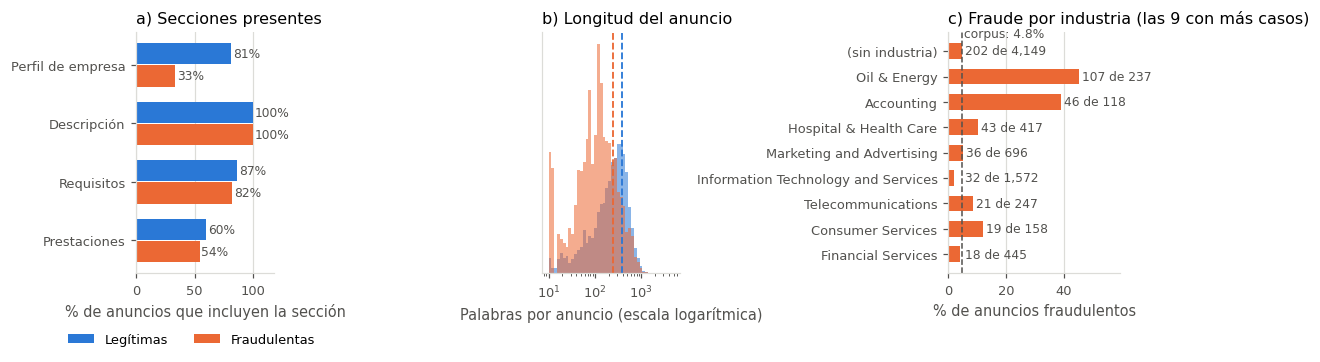

Tasa de fraude por industria, entre las que tienen al menos 25 casos:
                                     fraudes  anuncios   tasa
industria                                                    
Accounting                                46       118  0.390
Hospital & Health Care                    43       417  0.103
Information Technology and Services       32      1572  0.020
Marketing and Advertising                 36       696  0.052
Oil & Energy                             107       237  0.451
(sin industria)                          202      4149  0.049

Campañas con más de un anuncio: 1,519 (38.4% de los anuncios). Entre las fraudulentas: 38.4%


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(10.4, 3.5), gridspec_kw={"width_ratios": [1, 1, 1.25]})
ax = ejes[0]
presencia = pd.DataFrame({"Legítimas": (n_sec[y == 0] > 0).mean(), "Fraudulentas": (n_sec[y == 1] > 0).mean()})
pos_y = np.arange(len(SECCIONES))[::-1]
ax.barh(pos_y + 0.19, presencia["Legítimas"] * 100, height=0.36, color=AZUL, label="Legítimas")
ax.barh(pos_y - 0.19, presencia["Fraudulentas"] * 100, height=0.36, color=NARANJA, label="Fraudulentas")
for k, s in enumerate(SECCIONES):
    ax.text(presencia.loc[s, "Legítimas"] * 100 + 1.5, pos_y[k] + 0.19, f"{presencia.loc[s, 'Legítimas']:.0%}", va="center", fontsize=8, color=GRIS)
    ax.text(presencia.loc[s, "Fraudulentas"] * 100 + 1.5, pos_y[k] - 0.19, f"{presencia.loc[s, 'Fraudulentas']:.0%}", va="center", fontsize=8, color=GRIS)
ax.set_yticks(pos_y, [NOMBRE_SEC[s] for s in SECCIONES])
ax.set_xlim(0, 118); ax.set_xlabel("% de anuncios que incluyen la sección")
ax.set_title("a) Secciones presentes", loc="left"); estilizar(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2)

ax = ejes[1]
cortes = np.logspace(1, 3.7, 45)
ax.hist(docs.loc[y == 0, "n_tokens"], bins=cortes, density=True, color=AZUL, alpha=0.55, label="Legítimas")
ax.hist(docs.loc[y == 1, "n_tokens"], bins=cortes, density=True, color=NARANJA, alpha=0.55, label="Fraudulentas")
for clase, color in ((0, AZUL), (1, NARANJA)):
    ax.axvline(docs.loc[y == clase, "n_tokens"].median(), color=color, linestyle="--", linewidth=1.2)
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel("Palabras por anuncio (escala logarítmica)")
ax.set_title("b) Longitud del anuncio", loc="left"); estilizar(ax, None)

ax = ejes[2]
por_ind = docs.assign(y=y).groupby("industria")["y"].agg(["sum", "count"])
por_ind["tasa"] = por_ind["sum"] / por_ind["count"]
top = por_ind.sort_values("sum", ascending=False).head(9).iloc[::-1]
ax.barh(top.index, top["tasa"] * 100, color=NARANJA, height=0.62)
for k, (nombre, f) in enumerate(top.iterrows()):
    ax.text(max(f["tasa"], y.mean()) * 100 + 1.0, k, f"{int(f['sum'])} de {int(f['count']):,}", va="center", fontsize=8, color=GRIS)
ax.axvline(y.mean() * 100, color=GRIS, linestyle="--", linewidth=1)
ax.text(y.mean() * 100 + 0.6, len(top) - 0.45, f"corpus: {y.mean():.1%}", fontsize=8, color=GRIS)
ax.set_xlim(0, top["tasa"].max() * 100 * 1.32); ax.set_xlabel("% de anuncios fraudulentos")
ax.set_title("c) Fraude por industria (las 9 con más casos)", loc="left"); estilizar(ax)
fig.tight_layout()
guardar(fig, "fig1_corpus")

INDUSTRIAS_EVAL = [i for i in por_ind.index[(por_ind["sum"] >= 25)] if i != "(sin industria)"]
print("Tasa de fraude por industria, entre las que tienen al menos 25 casos:")
print(por_ind.loc[INDUSTRIAS_EVAL + ["(sin industria)"]].rename(
    columns={"sum": "fraudes", "count": "anuncios"}).round(3).to_string())
tamanos = docs.assign(y=y).groupby("campana")["y"].agg(["size", "max"])
print(f"\nCampañas con más de un anuncio: {(tamanos['size'] > 1).sum():,} "
      f"({docs['campana'].map(tamanos['size']).gt(1).mean():.1%} de los anuncios). "
      f"Entre las fraudulentas: {docs.loc[y == 1, 'campana'].map(tamanos['size']).gt(1).mean():.1%}")

La tabla de la sección 4 y la figura anterior resumen tres hechos que condicionan todo lo demás. Primero, las ofertas falsas omiten información: solo el 33 % incluye el perfil de la empresa, contra el 81 % de las legítimas, mientras que la descripción, los requisitos y las prestaciones aparecen casi con la misma frecuencia. Segundo, son más cortas. Tercero, el fraude no se reparte parejo: es el 45 % de los anuncios de *Oil & Energy* y el 39 % de los de *Accounting*, pero solo el 2 % de los de tecnología. Además, el 38 % de los anuncios pertenece a una campaña con más de un anuncio, y la proporción es la misma entre los fraudulentos.

## 6.2 Diferencias rasgo por rasgo dentro de una misma industria

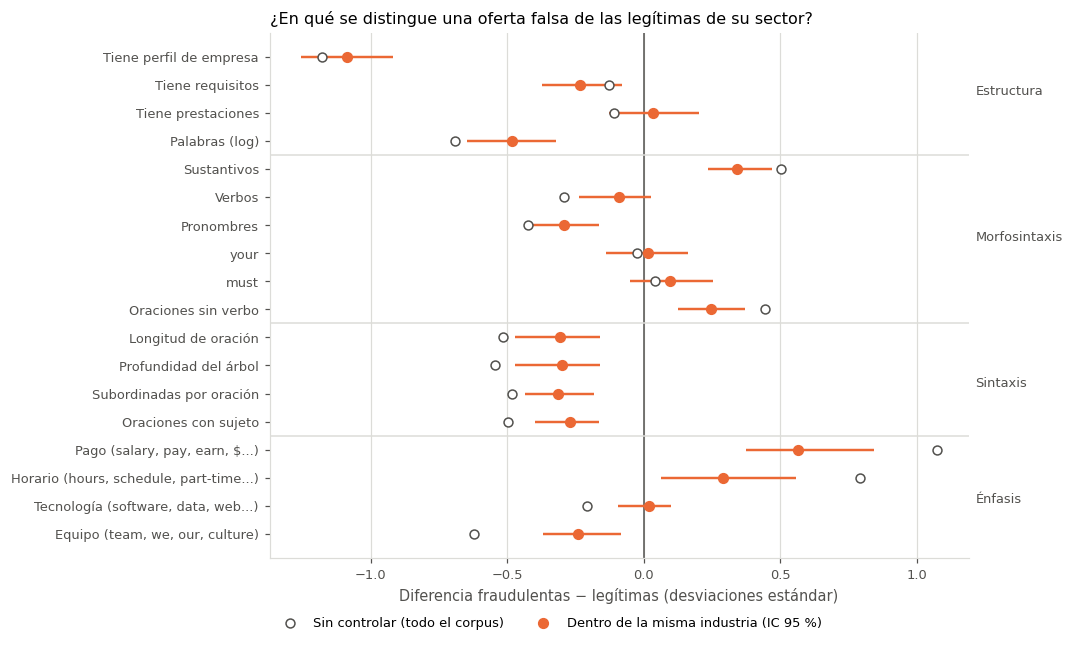

                                                 grupo  global  dentro  ic_inf  ic_sup  significativo
Tiene perfil de empresa                     Estructura   -1.18   -1.08   -1.25   -0.92           True
Tiene requisitos                            Estructura   -0.13   -0.23   -0.37   -0.08           True
Tiene prestaciones                          Estructura   -0.11    0.03   -0.13    0.20          False
Palabras (log)                              Estructura   -0.69   -0.48   -0.65   -0.32           True
Sustantivos                              Morfosintaxis    0.50    0.34    0.24    0.47           True
Verbos                                   Morfosintaxis   -0.29   -0.09   -0.24    0.02          False
Pronombres                               Morfosintaxis   -0.42   -0.29   -0.42   -0.16           True
your                                     Morfosintaxis   -0.02    0.01   -0.14    0.16          False
must                                     Morfosintaxis    0.04    0.10   -0.05    

In [6]:
legibles = pd.concat([estructura.drop(columns=["Oraciones (log)", "Palabras en descripción (log)",
                                               "Palabras en requisitos (log)", "Palabras en prestaciones (log)",
                                               "Palabras en perfil (log)"]),
                      morfo[["Sustantivos", "Verbos", "Pronombres", "your", "must", "Oraciones sin verbo"]],
                      sintaxis[["Longitud de oración", "Profundidad del árbol", "Subordinadas por oración",
                                "Oraciones con sujeto"]], enfasis], axis=1)
GRUPO = (["Estructura"] * 4 + ["Morfosintaxis"] * 6 + ["Sintaxis"] * 4 + ["Énfasis"] * 4)
Z = ((legibles - legibles.mean()) / legibles.std()).to_numpy()

def diferencia_dentro(idx):
    """Diferencia media (fraude - legítimas) en desviaciones estándar, comparando dentro de cada industria."""
    d = pd.DataFrame(Z[idx]); d["ind"] = ind_codigo[idx]; d["y"] = y[idx]
    medias = d.groupby(["ind", "y"]).mean().unstack("y")
    n = d.groupby(["ind", "y"]).size().unstack("y").reindex(medias.index)
    ok = (n[0] >= 5) & (n[1] >= 5)
    dif = (medias.xs(1, axis=1, level="y") - medias.xs(0, axis=1, level="y"))[ok]
    return (dif.mul(n[1][ok], axis=0).sum() / n[1][ok].sum()).to_numpy()

todos = np.arange(len(y))
crudo_d = Z[y == 1].mean(axis=0) - Z[y == 0].mean(axis=0)
dentro_d = diferencia_dentro(todos[con_industria])
boot = np.array([diferencia_dentro(i[con_industria[i]]) for i in remuestras(400)])
ic = np.percentile(boot, [2.5, 97.5], axis=0)
efectos = pd.DataFrame({"grupo": GRUPO, "global": crudo_d, "dentro": dentro_d, "ic_inf": ic[0], "ic_sup": ic[1]},
                       index=legibles.columns)
efectos["significativo"] = (efectos["ic_inf"] > 0) | (efectos["ic_sup"] < 0)
efectos.round(3).to_csv(RESULTADOS / "tabla_efectos.csv")

fig, ax = plt.subplots(figsize=(8.2, 6.2))
pos_y = np.arange(len(efectos))[::-1]
ax.axvline(0, color=GRIS, linewidth=1)
ax.hlines(pos_y, efectos["ic_inf"], efectos["ic_sup"], color=NARANJA, linewidth=1.6)
ax.scatter(efectos["global"], pos_y, s=34, facecolor="white", edgecolor=GRIS, zorder=3, label="Sin controlar (todo el corpus)")
ax.scatter(efectos["dentro"], pos_y, s=40, color=NARANJA, zorder=4, label="Dentro de la misma industria (IC 95 %)")
ax.set_yticks(pos_y, efectos.index)
for corte in np.cumsum([4, 6, 4])[:3]:
    ax.axhline(len(efectos) - corte - 0.5, color=REJILLA, linewidth=1)
for nombre, centro in zip(["Estructura", "Morfosintaxis", "Sintaxis", "Énfasis"], [1.5, 6.5, 11.5, 15.5]):
    ax.text(1.01, 1 - (centro + 0.5) / len(efectos), nombre, transform=ax.transAxes, fontsize=8.5, color=GRIS, va="center")
ax.set_xlabel("Diferencia fraudulentas − legítimas (desviaciones estándar)")
ax.set_title("¿En qué se distingue una oferta falsa de las legítimas de su sector?", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.09), ncol=2); estilizar(ax)
guardar(fig, "fig2_efectos")
print(efectos.round(2).to_string())

La figura anterior compara cada rasgo de dos maneras. El círculo vacío es la diferencia en todo el corpus y el punto naranja es la diferencia cuando una oferta falsa solo se compara con las legítimas de su industria. Casi todos los puntos naranjas quedan más cerca del cero que los círculos, es decir, **parte de cada diferencia era el sector y no el fraude**.

Tres grupos de rasgos sobreviven al control:

- **Omisión.** La falta de perfil de empresa es la diferencia más grande (−1.08 desviaciones estándar) y casi no cambia con el control. Los anuncios también son más cortos (−0.48).
- **Sintaxis más simple.** Las cuatro medidas sintácticas bajan cerca de 0.3 desviaciones: oraciones más cortas, árboles menos profundos, menos subordinadas y menos oraciones con sujeto. En la gramática hay más sustantivos (+0.34), más oraciones sin verbo (+0.24) y menos pronombres (−0.29).
- **Énfasis en el pago.** Las menciones de pago suben 0.57 desviaciones y las de horario 0.29, y bajan las de equipo (−0.24).

Otros rasgos no sobreviven. Las menciones de tecnología pasan de −0.21 a 0.02: esa diferencia era solo el sector. El pago baja de 1.07 a 0.57, así que casi la mitad de su efecto aparente también era el sector. El uso de `your` y de `must`, que en la Práctica 3 parecía distinguir al fraude, no es significativo con este control, y tampoco la proporción de verbos.

## 6.3 Capacidad de cada capa para separar las clases

Validación cruzada por campañas: 139 s


Azar: AUC 0.5, precisión promedio 0.048. Entre corchetes, IC 95 % (500 remuestras de campañas)

                                                     AUC global AUC dentro de industria                   Caída    Precisión promedio
Capa                                                                                                                                 
Tema (solo industria)                      0.733 [0.703, 0.763]               no aplica               no aplica  0.184 [0.146, 0.231]
Omisión y estructura                       0.773 [0.742, 0.797]    0.734 [0.687, 0.781]   0.039 [-0.003, 0.082]  0.149 [0.126, 0.181]
Léxico                                     0.973 [0.966, 0.980]    0.971 [0.960, 0.981]   0.002 [-0.008, 0.012]  0.827 [0.791, 0.858]
Morfosintaxis                              0.766 [0.735, 0.791]    0.723 [0.666, 0.772]    0.044 [0.002, 0.092]  0.128 [0.107, 0.157]
Sintaxis                                   0.662 [0.614, 0.704]    0.669 [0.625, 0.712]  -0.007 [-0.

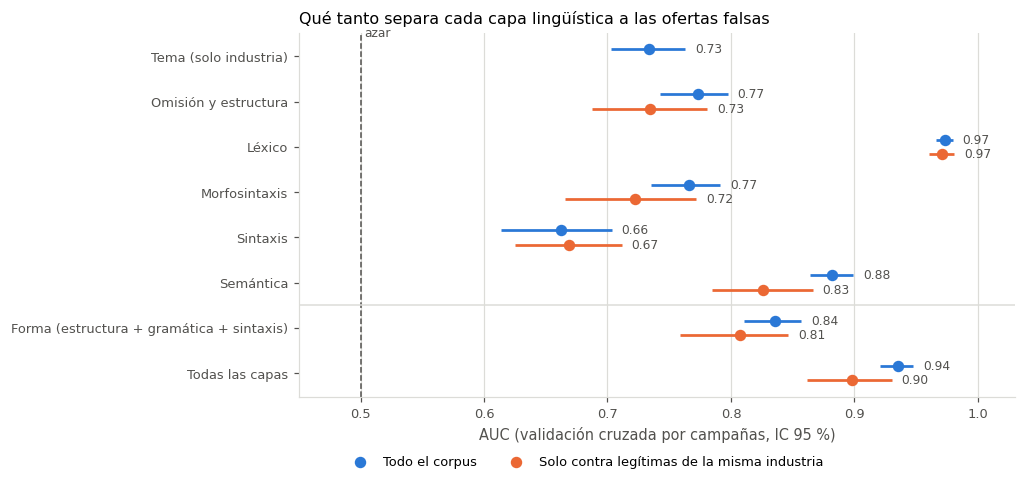

In [7]:
t0 = time.time()
kf_grupos = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(np.zeros(len(y)), y, campana))
P_GRUPOS = {capa: puntajes_cv(capa, kf_grupos) for capa in CAPAS}
print(f"Validación cruzada por campañas: {time.time() - t0:.0f} s")

N_BOOT = 500
boot = {capa: [] for capa in CAPAS}
for idx in remuestras(N_BOOT):
    for capa in CAPAS:
        boot[capa].append(metricas(y[idx], P_GRUPOS[capa][idx], ind_codigo[idx], con_industria[idx]))
filas = []
for capa in CAPAS:
    m = metricas(y, P_GRUPOS[capa], ind_codigo, con_industria)
    b = pd.DataFrame(boot[capa])
    caida = b["AUC global"] - b["AUC dentro de industria"]
    fila = {"Capa": capa}
    for k in m:
        fila[k] = m[k]; fila[k + " inf"], fila[k + " sup"] = intervalo(b[k])
    fila["Caída"] = m["AUC global"] - m["AUC dentro de industria"]
    fila["Caída inf"], fila["Caída sup"] = intervalo(caida)
    filas.append(fila)
principal = pd.DataFrame(filas).set_index("Capa")
# Con solo la industria, todos los anuncios de un sector empatan: la comparación interna no está definida.
principal.loc[CAPAS[0], [c for c in principal.columns if c.startswith(("AUC dentro", "Caída"))]] = np.nan
principal.round(4).to_csv(RESULTADOS / "tabla2_capas.csv")

def celda(f, k):
    return "no aplica" if np.isnan(f[k]) else f"{f[k]:.3f} [{f[k + ' inf']:.3f}, {f[k + ' sup']:.3f}]"
tabla2 = pd.DataFrame({k: [celda(f, k) for _, f in principal.iterrows()]
                       for k in ["AUC global", "AUC dentro de industria", "Caída", "Precisión promedio"]}, index=principal.index)
print(f"Azar: AUC 0.5, precisión promedio {y.mean():.3f}. Entre corchetes, IC 95 % ({N_BOOT} remuestras de campañas)\n")
print(tabla2.to_string())

fig, ax = plt.subplots(figsize=(8.4, 4.3))
pos_y = np.arange(len(CAPAS))[::-1]
for k, color, dy, etiqueta in (("AUC global", AZUL, 0.16, "Todo el corpus"),
                               ("AUC dentro de industria", NARANJA, -0.16, "Solo contra legítimas de la misma industria")):
    ax.hlines(pos_y + dy, principal[k + " inf"], principal[k + " sup"], color=color, linewidth=1.8)
    ax.scatter(principal[k], pos_y + dy, s=42, color=color, zorder=3, label=etiqueta)
    for v, sup, yy in zip(principal[k], principal[k + " sup"], pos_y + dy):
        if not np.isnan(v):
            ax.text(sup + 0.008, yy, f"{v:.2f}", va="center", fontsize=8, color=GRIS)
ax.axvline(0.5, color=GRIS, linestyle="--", linewidth=1); ax.text(0.503, len(CAPAS) - 0.55, "azar", fontsize=8, color=GRIS)
ax.axhline(1.5, color=REJILLA, linewidth=1)
ax.set_yticks(pos_y, CAPAS); ax.set_xlim(0.45, 1.03); ax.set_xlabel("AUC (validación cruzada por campañas, IC 95 %)")
ax.set_title("Qué tanto separa cada capa lingüística a las ofertas falsas", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.13), ncol=2); estilizar(ax)
guardar(fig, "fig3_capas")

La tabla y la figura anteriores contienen el resultado principal. Para leerlos conviene empezar por la primera fila: **un modelo que solo conoce la industria, sin leer el anuncio, obtiene un AUC de 0.73**. Cualquier resultado global de este corpus hay que compararlo contra ese número y no contra 0.5.


*La caída es el AUC global menos el AUC dentro de industria. Con solo la industria, todos los anuncios de un sector empatan y la comparación interna no está definida. Azar: AUC 0.5 y precisión promedio 0.048.*

**El léxico no pierde nada dentro de la industria** (0.973 contra 0.971; la caída de 0.002 no se distingue de cero). Es la capa más fuerte por mucho y también la única con una precisión promedio alta (0.83). Esto contradice la hipótesis H1.

**La semántica es la capa que más pierde** (0.056, con un intervalo que excluye el cero). Tiene sentido: el vector de un anuncio resume sobre todo de qué trata, y eso es justamente lo que el control elimina.

**Los rasgos de forma casi no dependen del sector.** Con 35 números que no incluyen ninguna palabra de contenido se llega a 0.84, y a 0.81 dentro de la industria. Por separado, la omisión y la morfosintaxis aportan más (0.73 y 0.72) que la sintaxis (0.67), que es la capa más débil aunque la más estable.

**Juntar todas las capas en un solo modelo no mejora al léxico** (0.935 contra 0.973). Como usé la misma regularización para todos los modelos, los 384 rasgos semánticos pesan demasiado en la combinación. La sección 6.7 revisa este punto con una combinación mejor hecha.

## 6.4 Cuánto inflan el resultado las copias

Grupos por campaña: 10,300 (506 con fraude). Grupos por plantilla: 5,082 (315 con fraude), el mayor con 827 anuncios


Las dos validaciones adicionales tardaron 285 s
Con validación simple, 35.6% de las ofertas falsas de prueba tiene en el entrenamiento una copia de su campaña, y 64.1% tiene un anuncio de su misma plantilla.

                                        Tema (solo industria)  Omisión y estructura  Léxico  Morfosintaxis  Sintaxis  Semántica  Forma (estructura + gramática + sintaxis)  Todas las capas
AUC simple                                              0.750                 0.788   0.981          0.781     0.670      0.918                                      0.852            0.956
AUC por campañas                                        0.733                 0.773   0.973          0.766     0.662      0.882                                      0.836            0.935
AUC por plantillas                                      0.709                 0.759   0.949          0.766     0.657      0.847                                      0.828            0.893
AP simple                              

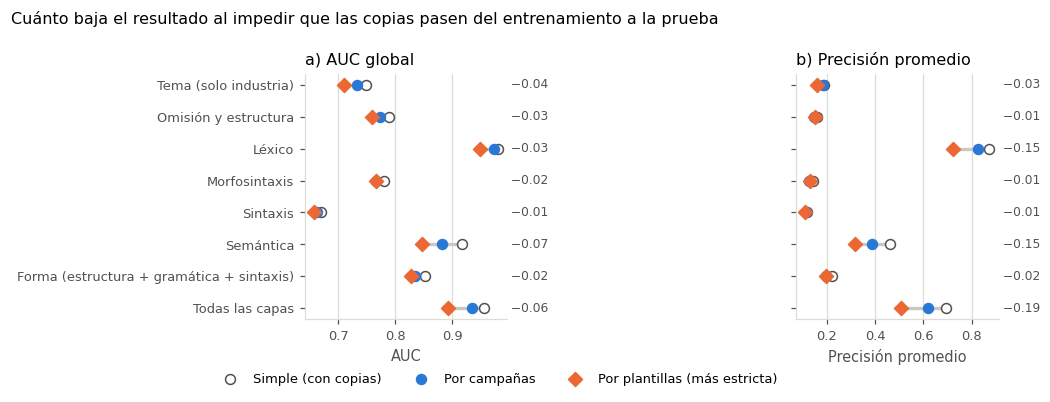

In [8]:
# Grupo más estricto: además de la campaña, se unen los anuncios que comparten una oración larga y poco común.
t0 = time.time()
donde = {}
with gzip.open(RUTA / "corpus_tokens.jsonl.gz", "rt", encoding="utf-8") as f:
    for i, linea in enumerate(f):
        for oracion in json.loads(linea)["oraciones"]:
            clave = re.sub(r"[^a-z ]", "", oracion.lower()).strip()
            if clave.count(" ") >= 7:                       # oraciones de 8 palabras o más
                donde.setdefault(clave, set()).add(i)
MAX_COPIAS = 10    # las frases que aparecen en más anuncios son fórmulas del género, no plantillas
origen, destino = list(range(len(y))), list(range(len(y)))
for anuncios in donde.values():
    if 2 <= len(anuncios) <= MAX_COPIAS:
        anuncios = sorted(anuncios)
        origen += [anuncios[0]] * (len(anuncios) - 1); destino += anuncios[1:]
primero = {}
for i, c in enumerate(campana):
    if c in primero:
        origen.append(primero[c]); destino.append(i)
    primero.setdefault(c, i)
n_plantillas, plantilla = connected_components(
    coo_matrix((np.ones(len(origen)), (origen, destino)), shape=(len(y), len(y))), directed=False)
del donde
print(f"Grupos por campaña: {len(np.unique(campana)):,} ({len(np.unique(campana[y == 1]))} con fraude). "
      f"Grupos por plantilla: {n_plantillas:,} ({len(np.unique(plantilla[y == 1]))} con fraude), "
      f"el mayor con {np.bincount(plantilla).max()} anuncios")

kf_simple = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(np.zeros(len(y)), y))
kf_plantilla = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(np.zeros(len(y)), y, plantilla))
P_SIMPLE = {capa: puntajes_cv(capa, kf_simple) for capa in CAPAS}
P_PLANTILLA = {capa: puntajes_cv(capa, kf_plantilla) for capa in CAPAS}
ESQUEMAS = {"simple": P_SIMPLE, "por campañas": P_GRUPOS, "por plantillas": P_PLANTILLA}
fuga = pd.DataFrame({f"{m} {e}": {c: f(y, P[c]) for c in CAPAS}
                     for m, f in (("AUC", roc_auc_score), ("AP", average_precision_score)) for e, P in ESQUEMAS.items()})
fuga["AUC dentro de industria por plantillas"] = [
    np.nan if c == CAPAS[0] else auc_dentro(y[con_industria], P_PLANTILLA[c][con_industria], ind_codigo[con_industria])
    for c in CAPAS]
fuga["Inflación AUC"] = fuga["AUC simple"] - fuga["AUC por plantillas"]
fuga["Inflación AP"] = fuga["AP simple"] - fuga["AP por plantillas"]
fuga.round(4).to_csv(RESULTADOS / "tabla3_fuga.csv")
compartidas = np.mean([np.isin(campana[te][y[te] == 1], campana[tr][y[tr] == 1]).mean() for tr, te in kf_simple])
compartidas_p = np.mean([np.isin(plantilla[te][y[te] == 1], plantilla[tr][y[tr] == 1]).mean() for tr, te in kf_simple])
print(f"Las dos validaciones adicionales tardaron {time.time() - t0:.0f} s")
print(f"Con validación simple, {compartidas:.1%} de las ofertas falsas de prueba tiene en el entrenamiento una copia "
      f"de su campaña, y {compartidas_p:.1%} tiene un anuncio de su misma plantilla.\n")
print(fuga.round(3).T.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
pos_y = np.arange(len(CAPAS))[::-1]
for ax, m, titulo in ((ejes[0], "AUC", "a) AUC global"), (ejes[1], "AP", "b) Precisión promedio")):
    ax.hlines(pos_y, fuga[f"{m} por plantillas"], fuga[f"{m} simple"], color=TENUE, linewidth=2.2)
    ax.scatter(fuga[f"{m} simple"], pos_y, s=42, facecolor="white", edgecolor=GRIS, zorder=3, label="Simple (con copias)")
    ax.scatter(fuga[f"{m} por campañas"], pos_y, s=42, color=AZUL, zorder=4, label="Por campañas")
    ax.scatter(fuga[f"{m} por plantillas"], pos_y, s=42, color=NARANJA, marker="D", zorder=5, label="Por plantillas (más estricta)")
    for v, yy in zip(fuga[f"Inflación {m}"], pos_y):
        ax.text(1.0, yy, f" −{v:.2f}", va="center", ha="left", fontsize=8, color=GRIS, transform=ax.get_yaxis_transform())
    ax.set_title(titulo, loc="left"); ax.set_xlabel(m if m == "AUC" else "Precisión promedio"); estilizar(ax)
ejes[0].set_yticks(pos_y, CAPAS)
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.95, -0.17), ncol=3)
fig.suptitle("Cuánto baja el resultado al impedir que las copias pasen del entrenamiento a la prueba", x=0.01, ha="left", fontsize=10.5)
fig.tight_layout()
guardar(fig, "fig4_fuga")

Con la validación simple, el 36 % de las ofertas falsas de prueba tiene en el entrenamiento un anuncio de su misma campaña, y el 64 % tiene uno de su misma plantilla. La figura y la tabla anteriores muestran el efecto de impedirlo.


El AUC baja poco (entre 0.01 y 0.07), pero la precisión promedio, que es la medida que importa con clases tan desbalanceadas, baja mucho en las capas que leen el contenido: el léxico pasa de 0.87 a 0.72 y la semántica de 0.46 a 0.32. Las capas de forma apenas se mueven (0.22 a 0.20). Es decir, **una parte del buen resultado del léxico y de la semántica consiste en reconocer plantillas ya vistas**, mientras que la forma no depende de eso. Aun con el control más estricto, el léxico conserva un AUC de 0.95 dentro de la industria.

## 6.5 Prueba en una industria nunca vista

Dejar una industria fuera: 160 s

Industria  Oil & Energy  Accounting  Hospital & Health Care  Marketing and Advertising  Information Technology and Services
Anuncios            237         118                     417                        696                                 1572
Fraudes             107          46                      43                         36                                   32 

                                           Oil & Energy  Accounting  Hospital & Health Care  Marketing and Advertising  Information Technology and Services  Promedio
Omisión y estructura                               0.76        0.86                    0.82                       0.71                                 0.66      0.76
Léxico                                             0.80        0.95                    0.78                       0.99                                 0.92      0.89
Morfosintaxis                                      0.67        0.77                    0.61   

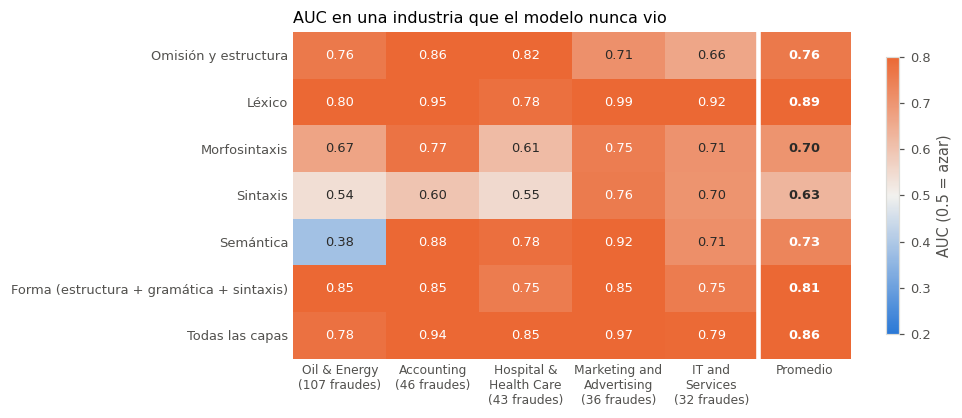

In [9]:
t0 = time.time()
loio = pd.DataFrame(index=CAPAS, columns=INDUSTRIAS_EVAL, dtype=float)
detalle = []
for ind in INDUSTRIAS_EVAL:
    te = np.where(industria == ind)[0]
    # También salen del entrenamiento las campañas que aparecen en la industria de prueba.
    tr = np.where((industria != ind) & ~np.isin(campana, campana[te]))[0]
    detalle.append({"Industria": ind, "Anuncios": len(te), "Fraudes": int(y[te].sum())})
    for capa in CAPAS[1:]:
        Xtr, Xte = matrices(capa, tr, te)
        loio.loc[capa, ind] = roc_auc_score(y[te], modelo().fit(Xtr, y[tr]).decision_function(Xte))
loio = loio.drop(index=CAPAS[0])
orden = pd.DataFrame(detalle).set_index("Industria").sort_values("Fraudes", ascending=False)
loio = loio[orden.index]
loio["Promedio"] = loio.mean(axis=1)
loio.round(4).to_csv(RESULTADOS / "tabla4_industria_fuera.csv")
print(f"Dejar una industria fuera: {time.time() - t0:.0f} s\n")
print(orden.T.to_string(), "\n")
print(loio.round(2).to_string())

fig, ax = plt.subplots(figsize=(9.2, 3.9))
im = ax.imshow(loio.to_numpy(), cmap=DIVERGENTE, vmin=0.2, vmax=0.8, aspect="auto")
for i in range(loio.shape[0]):
    for j in range(loio.shape[1]):
        v = loio.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v - 0.5) > 0.22 else "#2b2a28", fontweight="bold" if j == loio.shape[1] - 1 else None)
CORTAS = {"Information Technology and Services": "IT and\nServices", "Hospital & Health Care": "Hospital &\nHealth Care",
          "Marketing and Advertising": "Marketing and\nAdvertising"}
etiquetas = [f"{CORTAS.get(c, c)}\n({orden.loc[c, 'Fraudes']} fraudes)" for c in orden.index] + ["Promedio"]
ax.set_xticks(range(loio.shape[1]), etiquetas, fontsize=8); ax.set_yticks(range(loio.shape[0]), loio.index)
ax.axvline(loio.shape[1] - 1.5, color="white", linewidth=3)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.85, label="AUC (0.5 = azar)")
ax.set_title("AUC en una industria que el modelo nunca vio", loc="left")
fig.tight_layout()
guardar(fig, "fig5_industria_fuera")

La figura anterior muestra el AUC cuando el modelo se entrena sin una industria y se evalúa en ella. Es la prueba más dura para la idea del atajo, porque el modelo no puede haber aprendido nada de ese sector.

El resultado más llamativo está en *Oil & Energy*, el sector con más fraude: **la capa semántica obtiene 0.38, por debajo del azar**. El modelo aprendió en los demás sectores a qué "suena" una oferta falsa, y en el sector petrolero las ofertas falsas suenan a lo contrario, porque copian anuncios técnicos de ingeniería. Ahí la forma (0.85) supera al léxico (0.80) y a todas las capas juntas (0.78).

En promedio, el léxico sigue siendo la mejor capa (0.89), pero varía entre 0.78 y 0.99 según el sector. La forma promedia 0.81 y es la más pareja: va de 0.75 a 0.85. La semántica va de 0.38 a 0.92.

## 6.6 Qué palabras usa el modelo léxico

In [10]:
vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True,
                      token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z+#'-]+\b", max_features=60_000)
X_lex = vec.fit_transform(docs["texto_limpio"])
coef = pd.Series(modelo().fit(X_lex, y).coef_[0], index=vec.get_feature_names_out())
presente = (X_lex > 0).astype(np.int8)

def concentracion(termino):
    """Entre los anuncios falsos que usan el término, qué parte viene de la industria que más lo usa."""
    usa = np.asarray(presente[:, vec.vocabulary_[termino]].todense()).ravel().astype(bool) & (y == 1)
    conteo = pd.Series(industria[usa]).value_counts()
    return int(usa.sum()), conteo.index[0], conteo.iloc[0] / usa.sum()

filas = []
for termino, peso in coef.sort_values(ascending=False).head(15).items():
    n, ind, parte = concentracion(termino)
    filas.append({"Término": termino, "Peso": round(peso, 2), "Fraudes que lo usan": n,
                  "Industria principal": ind, "% en esa industria": f"{parte:.0%}"})
terminos = pd.DataFrame(filas)
terminos.to_csv(RESULTADOS / "tabla5_terminos.csv", index=False)
print("Términos con más peso hacia 'fraudulenta' en el modelo léxico (entrenado con todo el corpus):\n")
print(terminos.to_string(index=False))

Xf = np.hstack([StandardScaler().fit_transform(DENSAS[c]) for c in FORMA])
nombres_forma = list(estructura.columns) + list(morfo.columns) + list(sintaxis.columns)
coef_forma = pd.Series(modelo().fit(Xf, y).coef_[0], index=nombres_forma).sort_values(key=abs, ascending=False)
coef_forma.round(3).to_csv(RESULTADOS / "tabla6_coeficientes_forma.csv")
print("\nCoeficientes más grandes del modelo de forma (rasgos estandarizados):")
print(coef_forma.head(10).round(2).to_string())

Términos con más peso hacia 'fraudulenta' en el modelo léxico (entrenado con todo el corpus):

         Término  Peso  Fraudes que lo usan    Industria principal % en esa industria
      below link  3.61                   40 Hospital & Health Care                80%
     using below  3.60                   39 Hospital & Health Care                79%
     apply using  3.32                   35 Hospital & Health Care                77%
       assistant  3.27                   89             Accounting                24%
      data entry  3.22                   89        (sin industria)                40%
            link  3.00                   60 Hospital & Health Care                53%
  administrative  2.86                  115        (sin industria)                38%
            earn  2.82                   93        (sin industria)                53%
        offshore  2.51                   49           Oil & Energy                80%
           entry  2.50                  102  

Como el léxico resistió los controles, revisé qué aprendió. La tabla anterior lista los términos con más peso hacia la clase fraudulenta.


Hay tres tipos de términos. Unos son de sector (`offshore`, `subsea`), como en la Práctica 2. Otros son restos de una plantilla (`apply using below link`, concentrada en un 80 % en salud). Pero el grupo más grande es distinto: `data entry`, `administrative`, `assistant`, `clerk`, `receptionist` y `earn` aparecen en muchas ofertas falsas repartidas entre industrias. Describen **el tipo de empleo que se ofrece como anzuelo**: trabajo de oficina que no pide calificación, con la promesa de ganar dinero.

## 6.7 Detector final: regularización, combinación de capas y modelo no lineal

Ajuste, apilamiento y modelo de árboles: 167 s

                                                C elegida (por pliegue)            AUC global AUC dentro de industria    Precisión promedio
Omisión y estructura                                  10, 10, 1, 10, 10  0.773 [0.742, 0.800]    0.734 [0.689, 0.781]  0.149 [0.128, 0.186]
Léxico                                               10, 10, 10, 10, 10  0.976 [0.970, 0.982]    0.973 [0.963, 0.983]  0.854 [0.817, 0.881]
Morfosintaxis                                0.01, 0.01, 0.01, 0.1, 0.1  0.766 [0.734, 0.789]    0.721 [0.666, 0.768]  0.130 [0.107, 0.160]
Sintaxis                                   0.01, 0.01, 0.01, 0.01, 0.01  0.665 [0.617, 0.705]    0.671 [0.635, 0.714]  0.118 [0.091, 0.147]
Semántica                                  0.01, 0.01, 0.01, 0.01, 0.01  0.902 [0.887, 0.916]    0.838 [0.800, 0.878]  0.430 [0.376, 0.486]
Forma (estructura + gramática + sintaxis)  0.01, 0.01, 0.01, 0.01, 0.01  0.838 [0.815, 0.856]    0.808 [0.763, 0

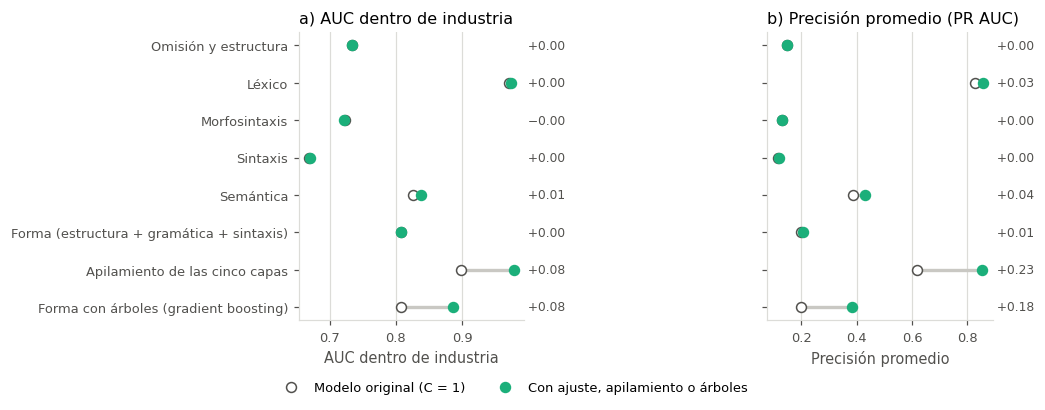

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier

t0 = time.time()
BASE = ["Omisión y estructura", "Léxico", "Morfosintaxis", "Sintaxis", "Semántica"]
VALORES_C = [0.01, 0.1, 1.0, 10.0]

def ajustar(Xtr, ytr, Xte, C):
    return LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=2000,
                              random_state=SEMILLA).fit(Xtr, ytr).decision_function(Xte)

P_AJUSTADO = {c: np.zeros(len(y)) for c in BASE + [CAPAS[6], "Apilamiento de las cinco capas"]}
P_ARBOLES = np.zeros(len(y))
C_ELEGIDA = {c: [] for c in BASE + [CAPAS[6]]}
for tr, te in kf_grupos:
    # Pliegues internos, también por campañas, que solo usan el entrenamiento de este pliegue.
    internos = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
                    .split(np.zeros(len(tr)), y[tr], campana[tr]))
    meta_tr, meta_te = [], []
    for capa in BASE + [CAPAS[6]]:
        Xtr, Xte = matrices(capa, tr, te)
        Xtr = csr_matrix(Xtr)
        internas = {}
        for C in VALORES_C:
            s = np.zeros(len(tr))
            for a, b in internos:
                s[b] = ajustar(Xtr[a], y[tr][a], Xtr[b], C)
            internas[C] = s
        mejor = max(VALORES_C, key=lambda C: average_precision_score(y[tr], internas[C]))
        C_ELEGIDA[capa].append(mejor)
        P_AJUSTADO[capa][te] = ajustar(Xtr, y[tr], Xte, mejor)
        if capa in BASE:
            meta_tr.append(internas[mejor]); meta_te.append(P_AJUSTADO[capa][te])
    # Apilamiento: un segundo modelo aprende cuánto confiar en el puntaje de cada capa.
    escala = StandardScaler().fit(np.column_stack(meta_tr))
    P_AJUSTADO["Apilamiento de las cinco capas"][te] = ajustar(
        escala.transform(np.column_stack(meta_tr)), y[tr], escala.transform(np.column_stack(meta_te)), 1.0)
    # Modelo no lineal con los 35 rasgos de forma.
    Xf_tr, Xf_te = (np.hstack([DENSAS[c][i] for c in FORMA]) for i in (tr, te))
    P_ARBOLES[te] = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMILLA).fit(
        Xf_tr, y[tr]).decision_function(Xf_te)

def fila_robustez(s):
    m = metricas(y, s, ind_codigo, con_industria)
    b = pd.DataFrame([metricas(y[i], s[i], ind_codigo[i], con_industria[i]) for i in remuestras(200)])
    return {k: f"{m[k]:.3f} [{intervalo(b[k])[0]:.3f}, {intervalo(b[k])[1]:.3f}]" for k in m} | {"_" + k: m[k] for k in m}

filas = {}
for capa in BASE + [CAPAS[6]]:
    filas[capa] = {"C elegida (por pliegue)": ", ".join(f"{c:g}" for c in C_ELEGIDA[capa])} | fila_robustez(P_AJUSTADO[capa])
filas["Apilamiento de las cinco capas"] = {"C elegida (por pliegue)": "—"} | fila_robustez(P_AJUSTADO["Apilamiento de las cinco capas"])
filas["Forma con árboles (gradient boosting)"] = {"C elegida (por pliegue)": "—"} | fila_robustez(P_ARBOLES)
robustez = pd.DataFrame(filas).T
robustez.to_csv(RESULTADOS / "tabla7_robustez.csv")
print(f"Ajuste, apilamiento y modelo de árboles: {time.time() - t0:.0f} s\n")
print(robustez[[c for c in robustez.columns if not c.startswith("_")]].to_string())

# Comparación con los modelos de C = 1 de la sección 6.3
antes = {c: c for c in BASE + [CAPAS[6]]} | {"Apilamiento de las cinco capas": "Todas las capas",
                                             "Forma con árboles (gradient boosting)": CAPAS[6]}
fig, ejes = plt.subplots(1, 2, figsize=(9.6, 3.9), sharey=True)
pos_y = np.arange(len(robustez))[::-1]
for ax, k, titulo in ((ejes[0], "AUC dentro de industria", "a) AUC dentro de industria"),
                      (ejes[1], "Precisión promedio", "b) Precisión promedio (PR AUC)")):
    previo = np.array([principal.loc[antes[c], k] for c in robustez.index])
    nuevo = robustez["_" + k].to_numpy(float)
    ax.hlines(pos_y, previo, nuevo, color=TENUE, linewidth=2.2)
    ax.scatter(previo, pos_y, s=42, facecolor="white", edgecolor=GRIS, zorder=3, label="Modelo original (C = 1)")
    ax.scatter(nuevo, pos_y, s=42, color=VERDE, zorder=4, label="Con ajuste, apilamiento o árboles")
    for v, p, yy in zip(nuevo, previo, pos_y):
        ax.text(1.0, yy, f" {v - p:+.2f}".replace("-", "−"), va="center", ha="left", fontsize=8, color=GRIS,
                transform=ax.get_yaxis_transform())
    ax.set_title(titulo, loc="left"); ax.set_xlabel(k.split(" (")[0]); estilizar(ax)
ejes[0].set_yticks(pos_y, robustez.index)
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.95, -0.17), ncol=2)
fig.tight_layout()
guardar(fig, "fig6_robustez")

La tabla y la figura anteriores repiten la evaluación por campañas con los tres cambios descritos en la sección 5.3.


**Ajustar la regularización casi no cambia nada.** Las capas pequeñas se mueven menos de 0.01 en cualquier métrica. Las únicas mejoras visibles son las de la semántica (precisión promedio de 0.39 a 0.43) y el léxico (de 0.83 a 0.85). El orden de las capas es el mismo, así que la comparación de la sección 6.3 no dependía de haber fijado C = 1.

**El apilamiento corrige la combinación, pero no supera al léxico.** Llega a un AUC de 0.980 y a 0.978 dentro de la industria, contra 0.976 y 0.973 del léxico solo, con la misma precisión promedio (0.85). Los intervalos se enciman. Es decir, lo que aportan las demás capas ya estaba casi todo en las palabras.

**Con un modelo no lineal, la forma sube bastante.** Los mismos 35 rasgos pasan de 0.84 a 0.91 de AUC, de 0.81 a 0.89 dentro de la industria y casi duplican su precisión promedio (de 0.20 a 0.38). El modelo lineal subestimaba esta capa: la señal está en combinaciones de rasgos, por ejemplo un anuncio sin perfil de empresa que además es corto y de oraciones simples. Aun así queda lejos del léxico en precisión promedio.

## 6.8 Desempeño del detector en la práctica

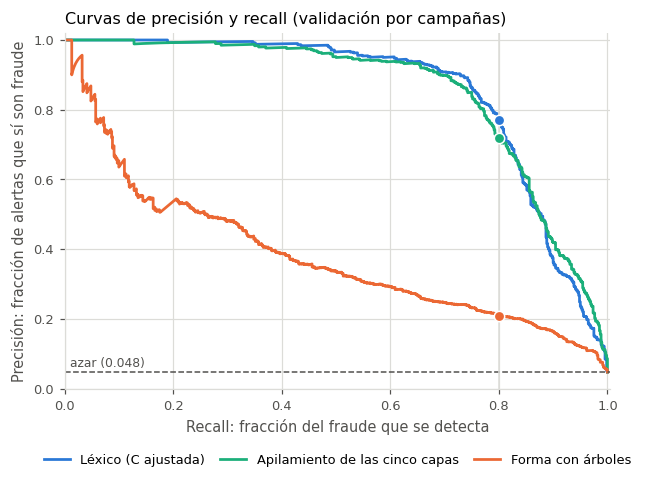

Anuncios evaluados: 14,265, de los cuales 680 son fraudulentos

                        Modelo Fraude detectado  Alertas  Fraudes entre las alertas  Falsas alarmas  Fraudes no detectados  Precisión        IC 95 %
           Léxico (C ajustada)              53%      370                        358              12                    322      0.968 [0.946, 0.995]
           Léxico (C ajustada)              80%      707                        544             163                    136      0.769 [0.570, 0.850]
           Léxico (C ajustada)              90%     1631                        612            1019                     68      0.375 [0.302, 0.533]
Apilamiento de las cinco capas              50%      357                        340              17                    340      0.952 [0.925, 0.984]
Apilamiento de las cinco capas              80%      756                        544             212                    136      0.720 [0.608, 0.834]
Apilamiento de las cinco capas            

In [12]:
from sklearn.metrics import precision_recall_curve

MODELOS_OP = {"Léxico (C ajustada)": (P_AJUSTADO["Léxico"], AZUL),
              "Apilamiento de las cinco capas": (P_AJUSTADO["Apilamiento de las cinco capas"], VERDE),
              "Forma con árboles": (P_ARBOLES, NARANJA)}
OBJETIVOS = [0.50, 0.80, 0.90]

def precision_a_recall(yv, s, objetivo):
    """Mayor precisión que se puede tener detectando al menos esa fracción del fraude, y el umbral que la da."""
    p, r, u = precision_recall_curve(yv, s)
    ok = np.where(r[:-1] >= objetivo)[0]
    k = ok[np.argmax(p[:-1][ok])]
    return p[k], r[k], u[k]

filas = []
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for nombre, (s, color) in MODELOS_OP.items():
    p, r, _ = precision_recall_curve(y, s)
    ax.plot(r, p, color=color, linewidth=1.8, label=nombre)
    for objetivo in OBJETIVOS:
        pr, re_, umbral = precision_a_recall(y, s, objetivo)
        alertas = int((s >= umbral).sum()); aciertos = int(((s >= umbral) & (y == 1)).sum())
        boot = [precision_a_recall(y[i], s[i], objetivo)[0] for i in remuestras(200)]
        filas.append({"Modelo": nombre, "Fraude detectado": f"{re_:.0%}", "Alertas": alertas,
                      "Fraudes entre las alertas": aciertos, "Falsas alarmas": alertas - aciertos,
                      "Fraudes no detectados": int(y.sum()) - aciertos, "Precisión": round(pr, 3),
                      "IC 95 %": f"[{intervalo(boot)[0]:.3f}, {intervalo(boot)[1]:.3f}]"})
        if objetivo == 0.80:
            ax.scatter([re_], [pr], s=46, color=color, edgecolor="white", zorder=4)
ax.axhline(y.mean(), color=GRIS, linestyle="--", linewidth=1)
ax.text(0.01, y.mean() + 0.015, f"azar ({y.mean():.3f})", fontsize=8, color=GRIS)
ax.axvline(0.80, color=REJILLA, linewidth=1)
ax.set_xlim(0, 1.005); ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall: fracción del fraude que se detecta"); ax.set_ylabel("Precisión: fracción de alertas que sí son fraude")
ax.set_title("Curvas de precisión y recall (validación por campañas)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, columnspacing=1.2); estilizar(ax, "both")
guardar(fig, "fig7_precision_recall")

operacion = pd.DataFrame(filas)
operacion.to_csv(RESULTADOS / "tabla8_operacion.csv", index=False)
print(f"Anuncios evaluados: {len(y):,}, de los cuales {int(y.sum())} son fraudulentos\n")
print(operacion.to_string(index=False))

Las métricas anteriores resumen todo el rango de umbrales. Para verlo en términos prácticos, la tabla y la figura anteriores muestran qué pasaría al usar el modelo para revisar los 14,265 anuncios, que incluyen 680 fraudulentos, según qué fracción del fraude se quiera detectar.


*El umbral de cada fila es el que da la mayor precisión detectando al menos esa fracción del fraude. Como se elige con los mismos puntajes que se evalúan, las cifras son algo optimistas.*

**El detector léxico es útil en la práctica.** Si se le pide detectar la mitad del fraude, casi no se equivoca: de 370 alertas, 358 son fraude real (precisión de 0.97). Para detectar el 80 % da 707 alertas, de las cuales 544 son fraude y 163 son falsas alarmas (precisión de 0.77), y se le escapan 136 ofertas falsas. Revisar 707 anuncios en lugar de 14,265 es una reducción de veinte veces.

**El último tramo es caro.** Para pasar del 80 % al 90 % del fraude, las falsas alarmas del léxico suben de 163 a 1,019 y la precisión cae a 0.38. Un grupo de ofertas falsas, cerca de una de cada diez, no se distingue de las legítimas por sus palabras. En ese tramo el apilamiento es un poco mejor (0.42), aunque los intervalos se enciman.

**La forma sola no alcanza para dar alertas.** Con los 35 rasgos de forma, detectar el 80 % del fraude cuesta 2,598 alertas y solo una de cada cinco es correcta. Sirve como señal complementaria y estable, no como detector único.

Por último guardo las cifras principales y listo los archivos generados.

In [13]:
numeros = {
    "documentos": int(len(docs)), "fraudulentos": int(y.sum()), "campanas": int(docs["campana"].nunique()),
    "campanas_fraude": int(docs.loc[y == 1, "campana"].nunique()),
    "principal": principal.round(4).to_dict("index"), "fuga": fuga.round(4).to_dict("index"),
    "industria_fuera": loio.round(4).to_dict("index"), "efectos": efectos.round(3).to_dict("index"),
    "copias_en_entrenamiento": round(float(compartidas), 4), "plantilla_en_entrenamiento": round(float(compartidas_p), 4),
    "grupos_plantilla": int(n_plantillas),
    "robustez": robustez.to_dict("index"),
    "operacion": operacion.to_dict("records"),
}
(RESULTADOS / "numeros.json").write_text(json.dumps(numeros, ensure_ascii=False, indent=1))
for ruta in sorted(list(FIGURAS.glob("*.png")) + list(RESULTADOS.glob("*"))):
    print(f"  {ruta.relative_to(AQUI)}")

  figuras/fig1_corpus.png
  figuras/fig2_efectos.png
  figuras/fig3_capas.png
  figuras/fig4_fuga.png
  figuras/fig5_industria_fuera.png
  figuras/fig6_robustez.png
  figuras/fig7_precision_recall.png
  resultados/numeros.json
  resultados/tabla1_corpus.csv
  resultados/tabla2_capas.csv
  resultados/tabla3_fuga.csv
  resultados/tabla4_industria_fuera.csv
  resultados/tabla5_terminos.csv
  resultados/tabla6_coeficientes_forma.csv
  resultados/tabla7_robustez.csv
  resultados/tabla8_operacion.csv
  resultados/tabla_efectos.csv


# 7. Discusión / Conclusiones

## 7.1 El detector y las hipótesis

**El objetivo se cumplió.** El detector léxico con la regularización ajustada alcanza un AUC de 0.98 y una precisión promedio de 0.85 con anuncios de campañas que no vio al entrenar. En la práctica detecta el 80 % del fraude revisando 707 de 14,265 anuncios, con tres de cada cuatro alertas correctas. Además no es un detector de sectores: mantiene 0.97 al compararse solo dentro de la industria y promedia 0.89 en industrias que nunca vio. Las tres hipótesis ayudan a explicar por qué.

**H1 quedó refutada.** Esperaba que el léxico se viniera abajo al controlar la industria, porque en la Práctica 2 las palabras más distintivas eran del sector petrolero. No ocurrió: el AUC es el mismo dentro de la industria (0.97) y llega a 0.89 en industrias no vistas. La explicación está en la diferencia entre los dos análisis. En la Práctica 2 ordené las palabras por cuánto más frecuentes eran en una clase, una por una, y ahí dominan las pocas palabras de un sector muy cargado de fraude. El modelo supervisado pondera miles de palabras a la vez y encuentra un vocabulario que cruza sectores: el de los empleos de oficina sin requisitos y el de ganar dinero (sección 6.6). Mi conclusión anterior de que "el léxico mide tema y no engaño" era demasiado fuerte. Lo correcto es que las palabras *más distintivas* miden el sector, y que debajo de ellas hay una señal léxica que no depende de él.

Hay dos matices. Esa señal no es engaño en sentido estricto, sino el tipo de puesto que los estafadores eligen como anzuelo, y un anuncio legítimo de captura de datos compartiría ese vocabulario. Además, una parte del resultado viene de reconocer plantillas, como muestra la caída de la precisión promedio de 0.87 a 0.72.

**H2 se sostuvo, sobre todo en la precisión promedio.** Ignorar las copias casi no cambia el AUC, pero infla la precisión promedio hasta en 0.19 (de 0.69 a 0.51 con todas las capas). Esto coincide con la advertencia de Kaufman et al. (2012): la fuga no se nota en todas las métricas, y la que se suele reportar con este corpus, la exactitud, es de las menos sensibles.

**H3 se sostuvo.** Los rasgos de forma dan 0.84 en todo el corpus, 0.81 dentro de la industria y 0.81 en industrias no vistas, y no dependen de las plantillas. Con un modelo no lineal llegan a 0.91 y a 0.89 dentro de la industria. Su desempeño es menor que el del léxico, sobre todo en precisión promedio (0.38 contra 0.85), pero es el más estable, y en el sector petrolero es la mejor capa. Esto concuerda con la literatura sobre engaño: Newman et al. (2003) encontraron menos pronombres y menor complejidad en los textos falsos, y aquí aparecen las dos cosas dentro de un mismo sector (pronombres −0.29; profundidad, subordinadas y longitud de oración cerca de −0.3). También concuerda con Vidros et al. (2017), que señalaron la falta de información de la empresa, la diferencia más grande que medí (−1.08).

## 7.2 El fraude imita a su sector

El resultado de la capa semántica en *Oil & Energy* (0.38) es la evidencia más clara de que el fraude copia el tema de su sector. Un modelo que aprende de qué hablan las ofertas falsas en general se equivoca de forma sistemática con las petroleras, porque estas hablan como un anuncio de ingeniería. Es el aprendizaje por atajos que describen Geirhos et al. (2020): la pista funciona con datos parecidos a los de entrenamiento y falla cuando cambia el contexto. El AUC de 0.73 del modelo que solo conoce la industria apunta a lo mismo: en este corpus se puede "detectar fraude" sin leer el anuncio.

## 7.3 Limitaciones y cómo mitigarlas

Cada limitación va acompañada de una acción posible para reducirla.

- **Pocos casos positivos.** Hay 680 ofertas falsas en 506 campañas, y las cinco industrias de la prueba final tienen entre 32 y 107. Por eso algunos intervalos son amplios y los resultados por industria deben leerse como tendencias. *Mitigación:* sumar ofertas fraudulentas de otras fuentes etiquetadas y repetir la validación con varias semillas para estabilizar las estimaciones.
- **Industria incompleta.** El 29 % de los anuncios no la declara, y el AUC dentro de industria solo usa los que sí. Además la industria la escribe quien publica, y un estafador puede elegirla. *Mitigación:* asignar la industria de forma automática, por ejemplo agrupando los vectores semánticos de los anuncios, para no depender del campo declarado.
- **Definición de campaña.** El umbral de 0.95 y la regla de las oraciones compartidas son decisiones mías. Una plantilla reescrita por completo no se detecta, así que todavía puede quedar algo de fuga. *Mitigación:* repetir la evaluación con varios umbrales y, si el corpus tuviera fechas, entrenar con anuncios antiguos y probar con los más recientes.
- **Ajuste limitado de los modelos.** Solo ajusté la regularización, y en varias capas el valor elegido quedó en el extremo de la rejilla (0.01 o 10). El modelo de árboles usa sus parámetros por defecto y solo lo probé con los rasgos de forma y con la validación por campañas. *Mitigación:* ampliar la rejilla, ajustar también el modelo de árboles y repetir con él y con el apilamiento la prueba de industria no vista.
- **Un solo corpus.** EMSCAD está en inglés, viene de una sola plataforma y de los años 2012 a 2014. Las etiquetas las pusieron empleados de esa plataforma y pueden tener errores. No sé si el detector funciona con estafas actuales. *Mitigación:* validarlo con un corpus reciente de otra plataforma y reentrenarlo cada cierto tiempo, porque los estafadores cambian sus textos.
- **Umbrales optimistas.** Los umbrales de la sección 6.8 se eligieron con los mismos puntajes que se evalúan y con la validación por campañas; con plantillas nunca vistas la precisión sería menor. *Mitigación:* fijar el umbral con un conjunto de validación separado y reportar el desempeño en un conjunto de prueba que no se use para nada más.
- **Falsas alarmas sobre empleos legítimos.** El detector aprende el tipo de empleo que se usa como anzuelo, así que un anuncio legítimo de captura de datos o de asistente puede recibir un puntaje alto. Los rasgos distinguen a las ofertas etiquetadas como falsas; no prueban que el autor escriba así *porque* miente. *Mitigación:* usar el detector para priorizar la revisión humana y no para bloquear anuncios, y combinarlo con señales que no son de texto, como la verificación de la empresa.

## 7.4 Conclusiones

1. **Se obtuvo un detector que funciona en este corpus.** Con las palabras del anuncio se alcanza un AUC de 0.98 y una precisión promedio de 0.85 sin copias entre entrenamiento y prueba. Detecta el 80 % del fraude con una precisión de 0.77 (707 alertas en 14,265 anuncios), pero llegar al 90 % multiplica por seis las falsas alarmas.
2. **El detector no depende del sector**, en contra de lo que supuse. Mantiene 0.97 dentro de la industria y 0.89 en industrias no vistas, porque usa el vocabulario de los empleos de oficina sin requisitos y de ganar dinero. Combinar las cinco capas por apilamiento no lo mejora.
3. **La forma de evaluar cambia el resultado.** Solo con la industria se obtiene un AUC de 0.73, y las copias inflan la precisión promedio hasta en 0.19. Un detector entrenado con EMSCAD que no agrupe las campañas ni controle la industria reporta un desempeño que no tendría en uso real.
4. **Los rasgos de forma son la señal más estable.** Omitir el perfil de la empresa, escribir menos y usar oraciones más simples distingue a las ofertas falsas dentro de cualquier sector (0.81) y en sectores no vistos (0.81) con solo 35 rasgos, y 0.89 dentro del sector con un modelo no lineal. No bastan como detector único, pero sirven de complemento cuando el vocabulario cambia.
5. **El fraude imita el tema de su sector.** La capa semántica es la que más pierde con el control (0.88 a 0.83) y se invierte en el sector petrolero (0.38), así que no conviene basar un detector en ella.

Como trabajo futuro propongo tres pasos: repetir la prueba de industria no vista con el modelo no lineal y con el apilamiento, validar el detector en un corpus de otra plataforma y de otros años, y repetir el análisis con ofertas en español.

# Referencias


Bird, S., Klein, E., y Loper, E. (2009). *Natural language processing with Python*. O'Reilly Media.

Geirhos, R., Jacobsen, J.-H., Michaelis, C., Zemel, R., Brendel, W., Bethge, M., y Wichmann, F. A. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence, 2*(11), 665–673. https://doi.org/10.1038/s42256-020-00257-z

Honnibal, M., Montani, I., Van Landeghem, S., y Boyd, A. (2020). *spaCy: Industrial-strength natural language processing in Python* [Software]. Zenodo. https://doi.org/10.5281/zenodo.1212303

Kaufman, S., Rosset, S., Perlich, C., y Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), Artículo 15. https://doi.org/10.1145/2382577.2382579

Newman, M. L., Pennebaker, J. W., Berry, D. S., y Richards, J. M. (2003). Lying words: Predicting deception from linguistic styles. *Personality and Social Psychology Bulletin, 29*(5), 665–675. https://doi.org/10.1177/0146167203029005010

Ott, M., Choi, Y., Cardie, C., y Hancock, J. T. (2011). Finding deceptive opinion spam by any stretch of the imagination. En *Proceedings of the 49th Annual Meeting of the Association for Computational Linguistics: Human Language Technologies* (pp. 309–319). Association for Computational Linguistics.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Reimers, N., y Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and the 9th International Joint Conference on Natural Language Processing* (pp. 3982–3992). Association for Computational Linguistics. https://doi.org/10.18653/v1/D19-1410

Vidros, S., Kolias, C., Kambourakis, G., y Akoglu, L. (2017). Automatic detection of online recruitment frauds: Characteristics, methods, and a public dataset. *Future Internet, 9*(1), Artículo 6. https://doi.org/10.3390/fi9010006